In [1]:
import os
import json
import csv
import time
from pathlib import Path
from typing import Annotated, TypedDict, Literal, Optional, Any

from dotenv import load_dotenv
load_dotenv()

if not os.environ.get("GROQ_API_KEY"):
    raise RuntimeError("Set GROQ_API_KEY in your .env file")

MAIN_MODEL = "groq:openai/gpt-oss-20b"
STRONG_MODEL = "groq:openai/gpt-oss-120b"

from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool
from langchain_core.messages import (
    AIMessage, HumanMessage, SystemMessage, BaseMessage, ToolMessage,
)

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

print("Ready. Main model:", MAIN_MODEL)

Ready. Main model: groq:openai/gpt-oss-20b


In [2]:
import os
import groq

client = groq.Groq(api_key=os.environ["GROQ_API_KEY"])

for m in client.models.list().data:
    print(m.id)

openai/gpt-oss-120b
whisper-large-v3
openai/gpt-oss-20b
canopylabs/orpheus-arabic-saudi
groq/compound-mini
qwen/qwen3.6-27b
allam-2-7b
meta-llama/llama-prompt-guard-2-86m
whisper-large-v3-turbo
qwen/qwen3.8-27b
openai/gpt-oss-safeguard-20b
canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-22m
groq/compound


In [3]:
# ============ Real Premier League 2024/25 Dataset ============

DATA_DIR = Path("Data")
TABLE_CSV = DATA_DIR / "Table.csv"
PLAYER_CSV = DATA_DIR / "Player_Stats.csv"
MATCHES_JSONL = DATA_DIR / "match_reports.jsonl"

for p in (TABLE_CSV, PLAYER_CSV, MATCHES_JSONL):
    if not p.exists():
        raise FileNotFoundError(f"Missing dataset file: {p.resolve()}")


def _load_table() -> list[dict[str, Any]]:
    with TABLE_CSV.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def _load_players() -> list[dict[str, Any]]:
    with PLAYER_CSV.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def _load_matches() -> list[dict[str, Any]]:
    records = []
    with MATCHES_JSONL.open(encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            rec = json.loads(line)
            # Each record is {"id":..., "match_report": {...}}
            mr = rec.get("match_report", rec)
            records.append(mr)
    return records


# Load once at import time (small files, fine to cache in memory)
TABLE_ROWS = _load_table()
PLAYER_ROWS = _load_players()
MATCH_REPORTS = _load_matches()

print(
    f"Loaded {len(TABLE_ROWS)} table rows, "
    f"{len(PLAYER_ROWS)} player rows, "
    f"{len(MATCH_REPORTS)} match reports."
)

Loaded 20 table rows, 574 player rows, 158 match reports.


In [4]:
# ============ Dataset Tools (deterministic, from real files) ============


def _to_int(v, default=0):
    try:
        return int(float(v))
    except (TypeError, ValueError):
        return default


def _to_float(v, default=0.0):
    try:
        return float(v)
    except (TypeError, ValueError):
        return default


@tool
def get_league_table(top_n: Optional[int] = None) -> str:
    """
    Return the Premier League 2024/25 league table.
    If top_n is given, return only the top N rows (e.g. top_n=4 for the top 4).
    """
    rows = sorted(TABLE_ROWS, key=lambda r: _to_int(r.get("Rk"), 999))
    if top_n:
        rows = rows[: int(top_n)]
    out = [{
        "position":       _to_int(r.get("Rk")),
        "team":           r.get("Squad"),
        "played":         _to_int(r.get("MP")),
        "wins":           _to_int(r.get("W")),
        "draws":          _to_int(r.get("D")),
        "losses":         _to_int(r.get("L")),
        "goals_for":      _to_int(r.get("GF")),
        "goals_against":  _to_int(r.get("GA")),
        "goal_diff":      _to_int(r.get("GD")),
        "points":         _to_int(r.get("Pts")),
        "points_per_match": _to_float(r.get("Pts/MP")),
        "xG":             _to_float(r.get("xG")),
        "xGA":            _to_float(r.get("xGA")),
        "xGD":            _to_float(r.get("xGD")),
        "xGD_per_90":     _to_float(r.get("xGD/90")),
        "top_team_scorer": r.get("Top Team Scorer"),
        "goalkeeper":     r.get("Goalkeeper"),
        "notes":          r.get("Notes"),
    } for r in rows]
    return json.dumps(out, ensure_ascii=False)


@tool
def get_player_stats(
    player_name: Optional[str] = None,
    team: Optional[str] = None,
    stat: Optional[str] = None,
    limit: int = 10,
) -> str:
    """
    Return Premier League 2024/25 player statistics.

    Filters (all optional, case-insensitive, substring match):
      - player_name: e.g. "Salah"
      - team:        e.g. "Liverpool"
      - stat:        one of 'goals','assists','G+A','minutes','starts','appearances'
                     Used to sort results (descending).

    If no filters, returns top `limit` scorers.

    Columns returned: Player, Nation, Pos, Squad, Age, MP, Starts, Min, 90s,
    Gls, Ast, G+A, G-PK, PK, PKatt, CrdY, CrdR, Gls/90, Ast/90, G+A-PK/90.
    """
    rows = PLAYER_ROWS

    if player_name:
        pn = player_name.lower()
        rows = [r for r in rows if pn in (r.get("Player", "") or "").lower()]
    if team:
        tn = team.lower()
        rows = [r for r in rows if tn in (r.get("Squad", "") or "").lower()]

    stat_key = {
        "goals":       "Performance_Gls",
        "assists":     "Performance_Ast",
        "g+a":         "Performance_G+A",
        "minutes":     "Playing Time_Min",
        "starts":      "Playing Time_Starts",
        "appearances": "Matches",
    }.get((stat or "goals").lower(), "Performance_Gls")

    def sort_val(r):
        v = r.get(stat_key, "0")
        try:
            return float(v)
        except (TypeError, ValueError):
            return 0.0

    rows = sorted(rows, key=sort_val, reverse=True)[: int(limit)]

    out = [{
        "player":       r.get("Player"),
        "nation":       r.get("Nation"),
        "position":     r.get("Pos"),
        "team":         r.get("Squad"),
        "age":          _to_int(r.get("Age")),
        "appearances":  _to_int(r.get("Matches")),
        "starts":       _to_int(r.get("Playing Time_Starts")),
        "minutes":      _to_int(r.get("Playing Time_Min")),
        "nineties":     _to_float(r.get("Playing Time_90s")),
        "goals":        _to_int(r.get("Performance_Gls")),
        "assists":      _to_int(r.get("Performance_Ast")),
        "goals_assists":_to_int(r.get("Performance_G+A")),
        "non_pen_goals":_to_int(r.get("Performance_G-PK")),
        "penalties":    _to_int(r.get("Performance_PK")),
        "penalties_att":_to_int(r.get("Performance_PKatt")),
        "yellow_cards": _to_int(r.get("Performance_CrdY")),
        "red_cards":    _to_int(r.get("Performance_CrdR")),
        "goals_per_90": _to_float(r.get("Per 90 Minutes_Gls")),
        "assists_per_90": _to_float(r.get("Per 90 Minutes_Ast")),
        "ga_pk_per_90": _to_float(r.get("Per 90 Minutes_G+A-PK")),
    } for r in rows]

    return json.dumps(out, ensure_ascii=False)


@tool
def get_match_fixtures(
    matchweek: Optional[int] = None,
    team: Optional[str] = None,
    limit: int = 20,
) -> str:
    """
    Return Premier League 2024/25 match fixtures / results from the match reports.

    Filters (all optional):
      - matchweek: e.g. 10
      - team:      substring, e.g. "Arsenal"

    Returns a compact result per match: matchweek, date, home, away,
    home_score, away_score, result, venue, attendance.
    """
    matches = []

    for mr in MATCH_REPORTS:
        mw = _to_int(mr.get("matchweek"))
        if matchweek is not None and mw != int(matchweek):
            continue

        teams = mr.get("teams", {}) or {}
        home = teams.get("home", {}) or {}
        away = teams.get("away", {}) or {}

        home_name = home.get("name") or home.get("team") or home.get("title")
        away_name = away.get("name") or away.get("team") or away.get("title")

        if team:
            t = team.lower()
            if t not in (home_name or "").lower() and t not in (away_name or "").lower():
                continue

        hs = home.get("score")
        as_ = away.get("score")
        # Fallback to explicit score keys
        if hs is None:
            hs = mr.get("home_score")
        if as_ is None:
            as_ = mr.get("away_score")

        hs_i = _to_int(hs) if hs is not None else None
        as_i = _to_int(as_) if as_ is not None else None

        if hs_i is not None and as_i is not None:
            result = ("Home Win" if hs_i > as_i
                      else "Away Win" if as_i > hs_i
                      else "Draw")
        else:
            result = None

        matches.append({
            "matchweek":   mw,
            "date":        mr.get("date"),
            "home_team":   home_name,
            "away_team":   away_name,
            "home_score":  hs_i,
            "away_score":  as_i,
            "result":      result,
            "venue":       mr.get("venue"),
            "attendance":  _to_int(mr.get("attendance")),
            "competition": mr.get("competition"),
        })

    matches.sort(key=lambda m: (m["matchweek"] or 0, m["date"] or ""))
    matches = matches[: int(limit)]
    return json.dumps(matches, ensure_ascii=False)

In [5]:
# ============ Subagents ============

stats_subagent = create_agent(
    model=STRONG_MODEL,
    tools=[get_player_stats, get_league_table],
    system_prompt=(
        "You are an expert statistical analyst for the Premier League 2024/25. "
        "Always use the provided dataset tools (get_player_stats, get_league_table) "
        "for any football statistics. Never invent statistics or answer from model "
        "knowledge when the requested information can be obtained from the dataset. "
        "If the dataset has no matching row, say so explicitly. "
        "Always respond in English."
    ),
)

fixtures_subagent = create_agent(
    model=MAIN_MODEL,
    tools=[get_match_fixtures],
    system_prompt=(
        "You report Premier League 2024/25 fixtures and results using the "
        "get_match_fixtures tool. Always use the tool - never invent fixtures, "
        "scores, or dates. If the dataset has no matching match, say so explicitly. "
        "Be concise. Always respond in English."
    ),
)


@tool
def call_stats_analyst(query: str) -> str:
    """Statistical analyst specialised in Premier League numbers and standings."""
    result = stats_subagent.invoke({"messages": [{"role": "user", "content": query}]})
    return result["messages"][-1].content


@tool
def call_fixtures_reporter(query: str) -> str:
    """Fixtures and results reporter for Premier League gameweeks."""
    result = fixtures_subagent.invoke({"messages": [{"role": "user", "content": query}]})
    return result["messages"][-1].content


SUBAGENT_TOOLS = {
    "call_stats_analyst": call_stats_analyst,
    "call_fixtures_reporter": call_fixtures_reporter,
}

print("Subagents and tools created.")

Subagents and tools created.


In [6]:
# ============ Guardrail + State ============

PREMIER_KEYWORDS = [
    "premier league", "epl", "arsenal", "liverpool",
    "manchester city", "man city", "man utd", "man united", "chelsea",
    "tottenham", "newcastle", "aston villa", "west ham",
    "everton", "brighton", "fulham", "brentford",
    "crystal palace", "wolverhampton", "wolves",
    "nottingham forest", "leicester", "southampton",
    "bournemouth", "ipswich", "gameweek", "matchweek", "fixture",
    "league table", "standings", "top scorer", "top 4", "top four",
    "salah", "haaland", "de bruyne", "van dijk",
    "goals", "assists", "xg", "player stats", "season 2024", "2024/25",
]

GUARDRAIL_REJECTION = """I only answer Premier League questions.
Ask me about:
- League table & standings
- Match fixtures & results
- Player stats
- Team performance
"""


def is_premier_league_question(text: str) -> bool:
    text = (text or "").lower()
    return any(k in text for k in PREMIER_KEYWORDS)


class AgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    blocked: bool

In [7]:
# ============ Nodes ============

def guardrail_node(state: AgentState) -> dict:
    last = state["messages"][-1]
    text = last.content if hasattr(last, "content") else str(last)
    if is_premier_league_question(text):
        return {"blocked": False}
    return {"blocked": True, "messages": [AIMessage(content=GUARDRAIL_REJECTION)]}


def route_after_guardrail(state: AgentState) -> Literal["supervisor", "end"]:
    return "end" if state.get("blocked") else "supervisor"


SUPERVISOR_PROMPT = SystemMessage(content=(
    "You are the main coordinator for a Premier League 2024/25 analysis system. "
    "You have access to two specialised subagents:\n"
    "- call_stats_analyst: for statistics, tables, top scorers, and player data.\n"
    "- call_fixtures_reporter: for fixtures and results.\n\n"
    "Guidelines:\n"
    "- Always respond in English.\n"
    "- Delegate tasks to the appropriate subagent using the tools.\n"
    "- The subagents read from a fixed 2024/25 dataset; do not add information "
    "from your own football knowledge.\n"
    "- Be enthusiastic about football ."
))

supervisor_model = init_chat_model(MAIN_MODEL).bind_tools(
    list(SUBAGENT_TOOLS.values())
)


def supervisor_node(state: AgentState) -> dict:
    messages = [SUPERVISOR_PROMPT] + state["messages"]
    response = supervisor_model.invoke(messages)
    return {"messages": [response]}


def route_after_supervisor(state: AgentState) -> Literal["tools", "end"]:
    last = state["messages"][-1]
    if getattr(last, "tool_calls", None):
        return "tools"
    return "end"


def tools_node(state: AgentState) -> dict:
    last = state["messages"][-1]
    tool_calls = getattr(last, "tool_calls", []) or []
    tool_messages: list[ToolMessage] = []

    for tc in tool_calls:
        name = tc["name"]
        args = tc["args"]
        call_id = tc["id"]

        if name not in SUBAGENT_TOOLS:
            tool_messages.append(ToolMessage(
                content=f"⚠️ Unknown tool `{name}`.", tool_call_id=call_id))
            continue

        tool_fn = SUBAGENT_TOOLS[name]
        result, last_error = None, None

        for attempt in range(3):
            try:
                result = tool_fn.invoke(args)
                break
            except Exception as e:
                last_error = e
                time.sleep(1.0 * (1.5 ** attempt))

        if result is None:
            result = f"⚠️ Tool `{name}` failed after retries: {last_error}"

        tool_messages.append(ToolMessage(content=str(result), tool_call_id=call_id))

    return {"messages": tool_messages}


print("Nodes defined.")

Nodes defined.


In [8]:
builder = StateGraph(AgentState)
builder.add_node("guardrail", guardrail_node)
builder.add_node("supervisor", supervisor_node)
builder.add_node("tools", tools_node)

builder.add_edge(START, "guardrail")
builder.add_conditional_edges("guardrail", route_after_guardrail,
                              {"supervisor": "supervisor", "end": END})
builder.add_conditional_edges("supervisor", route_after_supervisor,
                              {"tools": "tools", "end": END})
builder.add_edge("tools", "supervisor")

graph = builder.compile()
print("LangGraph compiled successfully.")

LangGraph compiled successfully.


In [9]:
def ask(question: str, max_len: int = 400) -> str:
    result = graph.invoke(
        {"messages": [HumanMessage(content=question)], "blocked": False})
    response = result["messages"][-1].content
    return response[:max_len] + "..." if len(response) > max_len else response


test_questions = [
    "Show me the fixtures for matchweek 10",
    "What is the Premier League standings?",
    "Show me Mohamed Salah's statistics",
    "What are the results for matchweek 3?",
    "Which teams are in the top 4?",
    "Who are the top scorers this season?",
    "What is the weather today?",
    "Tell me about La Liga",
]

for q in test_questions:
    print(f"❓ {q}\n{'-' * 40}")
    try:
        print(f"🤖 {ask(q)}\n{'-' * 60}\n")
    except Exception as e:
        print(f"❌ Error: {e}\n")

❓ Show me the fixtures for matchweek 10
----------------------------------------
🤖 Sure thing! Here are the matchday‑10 fixtures from the 2024/25 Premier League season (all games played on 2–4 Nov 2024):

| Date | Home vs. Away |
|------|---------------|
| 02 Nov 2024 | Newcastle United vs Arsenal |
| 02 Nov 2024 | Liverpool vs Brighton & Hove Albion |
| 02 Nov 2024 | Nottingham Forest vs West Ham United |
| 02 Nov 2024 | Ipswich Town vs Leicester City |
| 02 Nov 2024 | Bournemo...
------------------------------------------------------------

❓ What is the Premier League standings?
----------------------------------------
🤖 Here’s the **final Premier League 2024/25 standings**—what a thrilling season it’s been! 🌟

| Pos | Team | Pld | W | D | L | GF | GA | GD | Pts |
|-----|------|-----|---|---|---|----|----|----|-----|
| 1 | Liverpool | 38 | 25 | 9 | 4 | 86 | 41 | **+45** | **84** |
| 2 | Arsenal | 38 | 20 | 14 | 4 | 69 | 34 | **+35** | **74** |
| 3 | Manchester City | 38 | 21 | 8 | 9

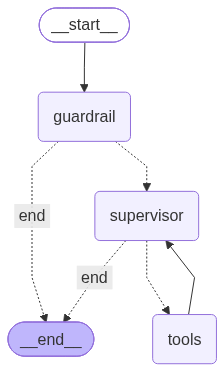

In [10]:
# ============ Visualise the LangGraph ============
# Requires: pip install grandalf  (or use mermaid / png)

try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualisation not available:", e)
    print(graph.get_graph().draw_mermaid())